```markdown
# **TP : Reconnaissance d'Empreintes Palmaires (Palmprint Recognition)**

Ce TP met en pratique les concepts clés du pipeline de reconnaissance biométrique palmaire vus en cours.

### **Objectifs et Étapes du TP :**

1. **Anatomie et caractéristiques de la paume :** Manipulation et visualisation de la base de données **THUPALMLAB** pour identifier visuellement les lignes principales (lignes de vie, de tête, de cœur) et les rides secondaires.
2. **Acquisition et extraction de la ROI (Region of Interest) :** Comprendre comment l'image brute est segmentée et recentrée sur un carré central de $224 \times 224$ pixels pour s'affranchir de la rotation, de la translation et du fond.
3. **Extraction de caractéristiques (Templates) :** Utilisation d'un CNN conçu de zéro puis de l'architecture *MobileNetV2* (Transfer Learning) pour projeter chaque ROI de paume sous forme d'un vecteur de caractéristiques dense (le *template* ou signature biométrique).
4. **Stockage et Appariement (Matching) par similarité cosinus :**
   * Stockage des signatures de référence.
   * Calcul de la distance/similarité entre un template d'évaluation (requête) et les templates stockés à l'aide de la **similarité cosinus**.
   * Application d'un **seuil de décision** pour accepter ou rejeter l'identité d'un utilisateur.
```

# **Étape 1 :** Importation des bibliothèques et configuration du GPU

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU disponible : []


# **Étape 2 :** Importation de l'archive ZIP du Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

if not zip_name.lower().endswith(".zip"):
    raise ValueError("Veuillez importer une archive ZIP.")

print("Dataset importé :", zip_name)

# **Étape 3 :** Extraction des fichiers du Dataset

In [ ]:
import zipfile

DATASET_PATH = "/content/THUPALMLAB"

os.makedirs(DATASET_PATH, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(DATASET_PATH)

print("Dataset prêt à être utilisé.")

Dataset prêt à être utilisé.


# **Étape 4 :** Exploration et Visualisation des images d'empreintes palmaires

In [ ]:
for root, dirs, filenames in os.walk(DATASET_PATH):

    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 3:

        indent = "    " * level

        print(f"{indent}{os.path.basename(root)}/")

        for filename in filenames[:8]:
            print(f"{indent}    {filename}")

THUPALMLAB/
    THUPALMLAB_224/
        39_r_7.jpg
        14_l_3.jpg
        67_l_5.jpg
        62_r_7.jpg
        38_l_4.jpg
        18_r_4.jpg
        157_l_1.jpg
        24_r_6.jpg


In [ ]:
# Définition de la variable 'image_paths' pour corriger l'erreur
image_dir = Path(DATASET_PATH)
image_paths = sorted(list(image_dir.rglob("*.jpg")))

print(f"Nombre total d'images trouvées : {len(image_paths)}")

Nombre total d'images trouvées : 1280


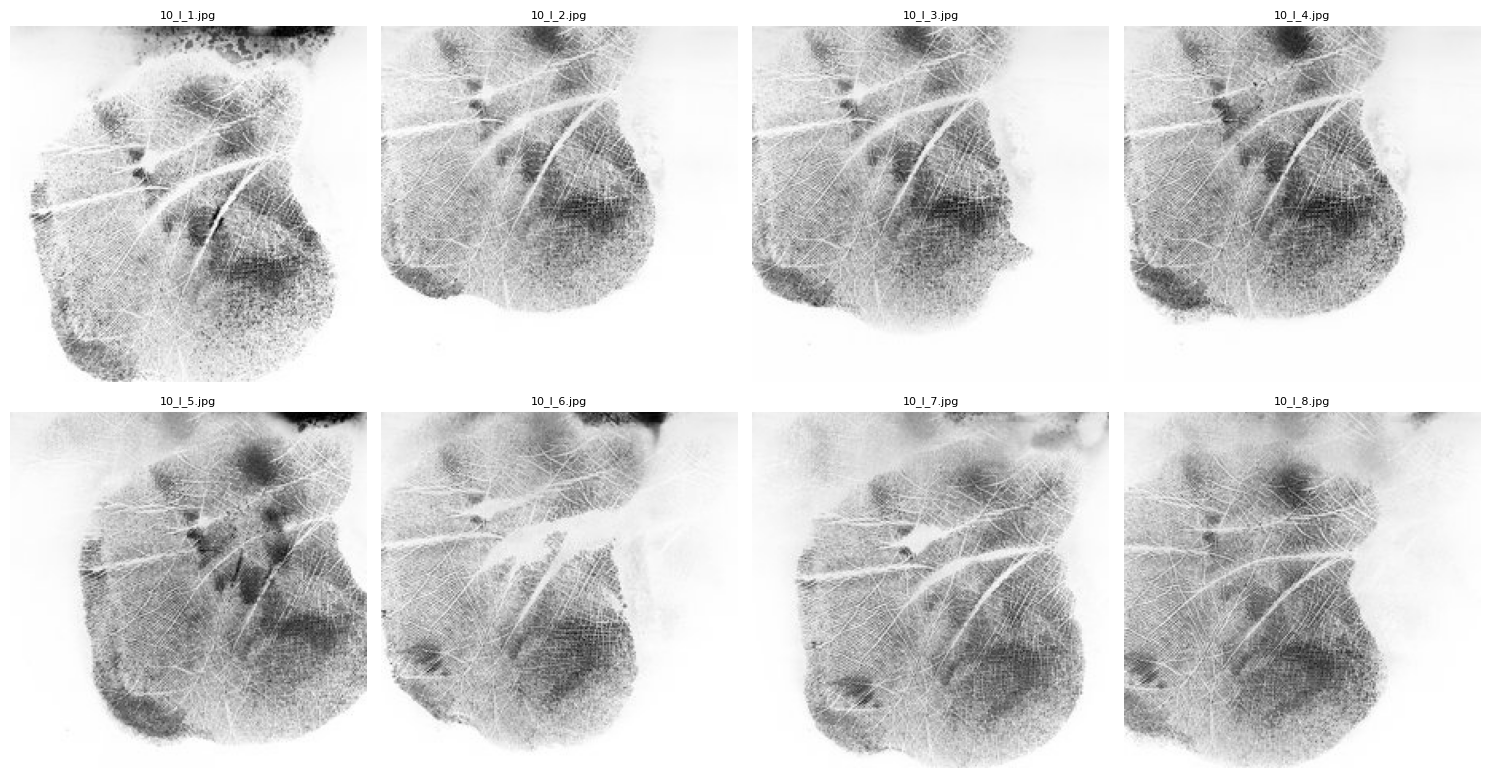

In [ ]:
plt.figure(figsize=(15, 8))

for i, path in enumerate(image_paths[:8]):

    img = Image.open(path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(os.path.basename(path), fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

```markdown
# **Étape 5 : Prétraitement et Extraction de la ROI (Region of Interest)**
Nous appliquons un prétraitement pour isoler la zone centrale utile (la paume) et la redimensionner à une taille uniforme.

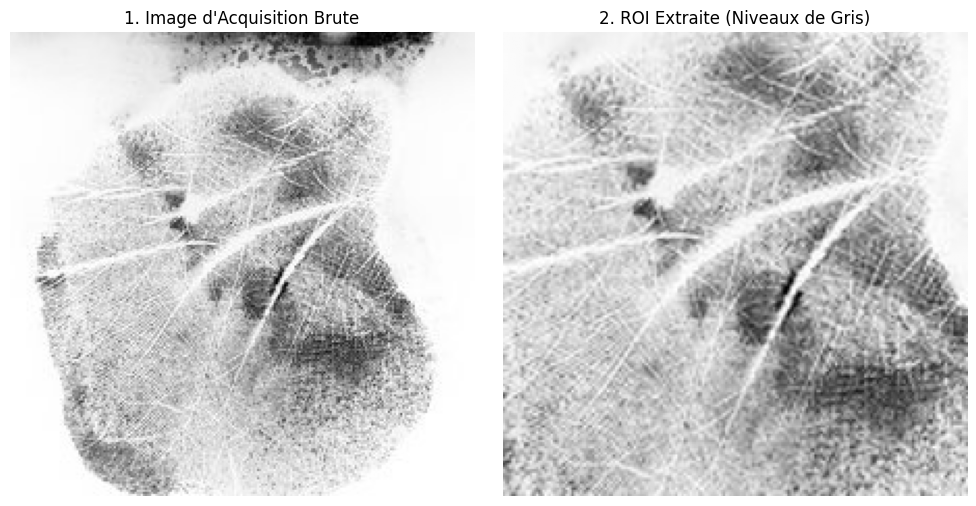

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def preprocess_and_extract_roi(image_path, target_size=(224, 224)):
    # 1. Lecture en niveaux de gris
    img_gray = Image.open(image_path).convert("L")

    # 2. Extraction directe de la ROI (Région centrale sans binarisation intermédiaire)
    w, h = img_gray.size
    crop_box = (int(w * 0.15), int(h * 0.15), int(w * 0.85), int(h * 0.85))
    img_roi = img_gray.crop(crop_box)

    # 3. Redimensionnement uniforme
    img_roi = img_roi.resize(target_size)

    # 4. Normalisation des pixels entre [0, 1]
    roi_array = np.array(img_roi) / 255.0
    return img_roi, roi_array

# Visualisation du processus d'extraction directe
original_path = image_paths[0]
original_img = Image.open(original_path)
roi_img, roi_arr = preprocess_and_extract_roi(original_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original_img, cmap='gray')
axes[0].set_title("1. Image d'Acquisition Brute")
axes[0].axis('off')

axes[1].imshow(roi_img, cmap='gray')
axes[1].set_title("2. ROI Extraite (Niveaux de Gris)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

```markdown
# **Étape 6 : Génération des Caractéristiques (Templates) et Stockage**
Nous convertissons chaque ROI en un descripteur numérique (Template) à l'aide d'un extracteur de caractéristiques (MobileNetV2), puis nous le sauvegardons dans un fichier local.

In [ ]:
import os
import numpy as np
import pickle
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

# Fonction de prétraitement sans binarisation
def preprocess_and_extract_roi(image_path, target_size=(224, 224)):
    img_gray = Image.open(image_path).convert("L")
    w, h = img_gray.size
    crop_box = (int(w * 0.15), int(h * 0.15), int(w * 0.85), int(h * 0.85))
    img_roi = img_gray.crop(crop_box)
    img_roi = img_roi.resize(target_size)
    roi_array = np.array(img_roi) / 255.0
    return img_roi, roi_array

# Initialisation du modèle d'extraction d'empreintes (MobileNetV2)
feature_extractor = MobileNetV2(weights='imagenet', include_top=False, pooling='avg', input_shape=(224, 224, 3))

def generate_template(image_path):
    # Utilisation de la ROI en niveaux de gris d'origine
    roi_img, _ = preprocess_and_extract_roi(image_path)

    # Conversion en RGB pour MobileNetV2
    img_rgb = roi_img.convert("RGB")
    x = img_to_array(img_rgb)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    # Extraction et normalisation du template
    template = feature_extractor.predict(x, verbose=0)[0]
    template = template / np.linalg.norm(template)
    return template

# Recréation de la base de données de référence avec les ROI en niveaux de gris
template_database = {}
registered_subjects = set()

for path in image_paths:
    subject_id = os.path.basename(path).split('_')[0]
    if subject_id not in registered_subjects:
        template_database[subject_id] = generate_template(path)
        registered_subjects.add(subject_id)

# Sauvegarde physique
DATABASE_FILE = "palmprint_templates.pkl"
with open(DATABASE_FILE, "wb") as f:
    pickle.dump(template_database, f)

print(f"Base de données mise à jour (sans binarisation) ! {len(template_database)} sujets enregistrés.")

Base de données mise à jour (sans binarisation) ! 80 sujets enregistrés.


```markdown
# **Étape 7 : Matching, Comparaison par Similarité Cosinus et Prise de Décision**
Lors de la présentation d'une nouvelle image requête (User d'authentification), nous extrayons sa signature biométrique, calculons la similarité cosinus par rapport à la base et décidons s'il s'agit d'un utilisateur accepté ou rejeté selon un seuil.

In [ ]:
import os
import numpy as np
import pickle

DATABASE_FILE = "palmprint_templates.pkl"

# Chargement de la base de données sauvegardée
with open(DATABASE_FILE, "rb") as f:
    saved_templates = pickle.load(f)

def verify_user(query_image_path, claimed_identity, threshold=0.75):
    # 1. Extraction du template pour l'image requête
    query_template = generate_template(query_image_path)

    if claimed_identity not in saved_templates:
        return "REJET (Identité revendiquée inexistante dans la base)", 0.0

    # 2. Calcul de la similarité cosinus avec l'empreinte de référence stockée
    reference_template = saved_templates[claimed_identity]
    similarity = np.dot(query_template, reference_template) / (np.linalg.norm(query_template) * np.linalg.norm(reference_template))

    # 3. Prise de décision par seuil
    decision = "ACCÈS AUTORISÉ (ACCEPTATION)" if similarity >= threshold else "ACCÈS REFUSÉ (REJET)"
    return decision, similarity

# Exemple 1 : Test d'authentification d'un utilisateur légitime (Même personne, autre image)
query_legitimate = [p for p in image_paths if "10_" in os.path.basename(p)][4]
decision_1, score_1 = verify_user(query_legitimate, claimed_identity="10", threshold=0.70)

# Exemple 2 : Test d'authentification d'un imposteur
query_impostor = [p for p in image_paths if "11_" in os.path.basename(p)][0]
decision_2, score_2 = verify_user(query_impostor, claimed_identity="10", threshold=0.70)

# Affichage des résultats pratiques du matching
print("=== SCÉNARIO 1 : UTILISATEUR LÉGITIME ===")
print(f"Identité revendiquée : Sujet 10 | Fichier utilisé : {os.path.basename(query_legitimate)}")
print(f"Score de similarité cosinus : {score_1:.4f}")
print(f"Décision finale : {decision_1}\n")

print("=== SCÉNARIO 2 : IMPOSTEUR ===")
print(f"Identité revendiquée : Sujet 10 | Fichier utilisé : {os.path.basename(query_impostor)}")
print(f"Score de similarité cosinus : {score_2:.4f}")
print(f"Décision finale : {decision_2}")

=== SCÉNARIO 1 : UTILISATEUR LÉGITIME ===
Identité revendiquée : Sujet 10 | Fichier utilisé : 10_l_5.jpg
Score de similarité cosinus : 0.7863
Décision finale : ACCÈS AUTORISÉ (ACCEPTATION)

=== SCÉNARIO 2 : IMPOSTEUR ===
Identité revendiquée : Sujet 10 | Fichier utilisé : 11_l_1.jpg
Score de similarité cosinus : 0.6211
Décision finale : ACCÈS REFUSÉ (REJET)


# **Fin du TP**

